<a href="https://colab.research.google.com/github/Dharanim42/lstm/blob/main/Language.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install tensorflow scikit-learn seaborn

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print(df.columns)
print(df.shape)

Saving archive (1).zip to archive (1).zip
Dataset loaded successfully!
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Index(['Text', 'language'], dtype='object')
(22000, 2)


In [ ]:

df.columns = df.columns.str.strip().str.lower()

df = df[["text", "language"]].dropna().copy()

df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["text"] != "") &
    (df["language"] != "")
].drop_duplicates().reset_index(drop=True)

print("Clean dataset:", df.shape)
print(df["language"].value_counts())


Clean dataset: (21858, 2)
language
Chinese       1000
English       1000
Romanian      1000
Persian       1000
Japanese      1000
Korean        1000
Thai          1000
Turkish       1000
Urdu          1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Keep up to 1000 samples per language
df = (
    df.groupby("language", group_keys=False)
      .apply(
          lambda x: x.sample(
              n=min(len(x), 1000),
              random_state=42
          )
      )
      .reset_index(drop=True)
)

X = df["text"].values

encoder = LabelEncoder()
y = encoder.fit_transform(df["language"])

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Character-level tokenizer
tokenizer = Tokenizer(
    char_level=True,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

max_len = 200

X_train = pad_sequences(
    tokenizer.texts_to_sequences(X_train_text),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

vocab_size = len(tokenizer.word_index) + 1
num_classes = len(encoder.classes_)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Vocabulary size:", vocab_size)
print("Number of languages:", num_classes)
print("Languages:", list(encoder.classes_))


/tmp/ipykernel_11714/2547296148.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Training data: (17486, 200)
Testing data: (4372, 200)
Vocabulary size: 6816
Number of languages: 22
Languages: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(max_len,)),
    Embedding(vocab_size, 64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       436,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 474,838 (1.81 MB)

 Trainable params: 474,838 (1.81 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)


Epoch 1/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 56s 210ms/step - accuracy: 0.3358 - loss: 1.9810 - val_accuracy: 0.5334 - val_loss: 1.3417
Epoch 2/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 49s 201ms/step - accuracy: 0.5753 - loss: 1.2388 - val_accuracy: 0.6792 - val_loss: 0.9054
Epoch 3/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 51s 206ms/step - accuracy: 0.6444 - loss: 0.9746 - val_accuracy: 0.6890 - val_loss: 0.8107
Epoch 4/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 51s 207ms/step - accuracy: 0.6868 - loss: 0.8554 - val_accuracy: 0.7479 - val_loss: 0.6964
Epoch 5/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 49s 200ms/step - accuracy: 0.7432 - loss: 0.6847 - val_accuracy: 0.7925 - val_loss: 0.5764
Epoch 6/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 82s 199ms/step - accuracy: 0.7419 - loss: 0.7075 - val_accuracy: 0.8165 - val_loss: 0.5046
Epoch 7/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 49s 199ms/step - accuracy: 0.8137 - loss: 0.5089 - val_accuracy: 0.8107 - val_loss: 0.5549
Epoch 8/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 52s 210ms/step - accuracy: 0.8438 - loss: 0

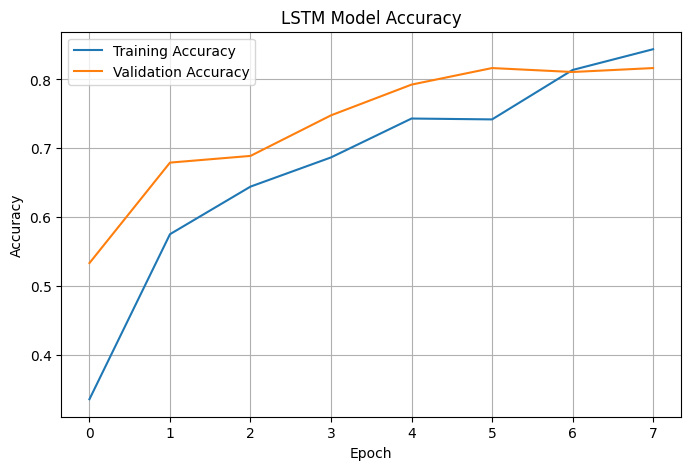

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

from sklearn.metrics import accuracy_score, classification_report

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


137/137 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step
Model Accuracy: 81.27 %

Classification Report:

              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99       200
     Chinese       0.99      0.97      0.98       200
       Dutch       0.69      0.31      0.43       199
     English       0.46      0.86      0.60       200
    Estonian       0.52      0.77      0.62       200
      French       0.58      0.82      0.68       198
       Hindi       1.00      0.96      0.98       198
  Indonesian       0.61      0.24      0.35       195
    Japanese       0.99      0.99      0.99       200
      Korean       1.00      0.98      0.99       200
       Latin       0.74      0.77      0.76       191
     Persian       0.99      0.94      0.96       200
   Portugese       0.54      0.38      0.45       199
      Pushto       0.93      0.92      0.93       199
    Romanian       0.73      0.94      0.82       200
     Russian       0.98      0.98      0.98 

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict the language
y_pred = np.argmax(model.predict(X_test), axis=1)

# Calculate evaluation metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("Recall   :", recall_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("F1-score :", f1_score(
    y_test, y_pred, average="macro", zero_division=0
))

# Display classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


137/137 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step
Accuracy : 0.8126715462031107
Precision: 0.8262315445155896
Recall   : 0.8118449506088805
F1-score : 0.8046066634902566

Classification Report:

              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99       200
     Chinese       0.99      0.97      0.98       200
       Dutch       0.69      0.31      0.43       199
     English       0.46      0.86      0.60       200
    Estonian       0.52      0.77      0.62       200
      French       0.58      0.82      0.68       198
       Hindi       1.00      0.96      0.98       198
  Indonesian       0.61      0.24      0.35       195
    Japanese       0.99      0.99      0.99       200
      Korean       1.00      0.98      0.99       200
       Latin       0.74      0.77      0.76       191
     Persian       0.99      0.94      0.96       200
   Portugese       0.54      0.38      0.45       199
      Pushto       0.93      0.92      0.93       199
 

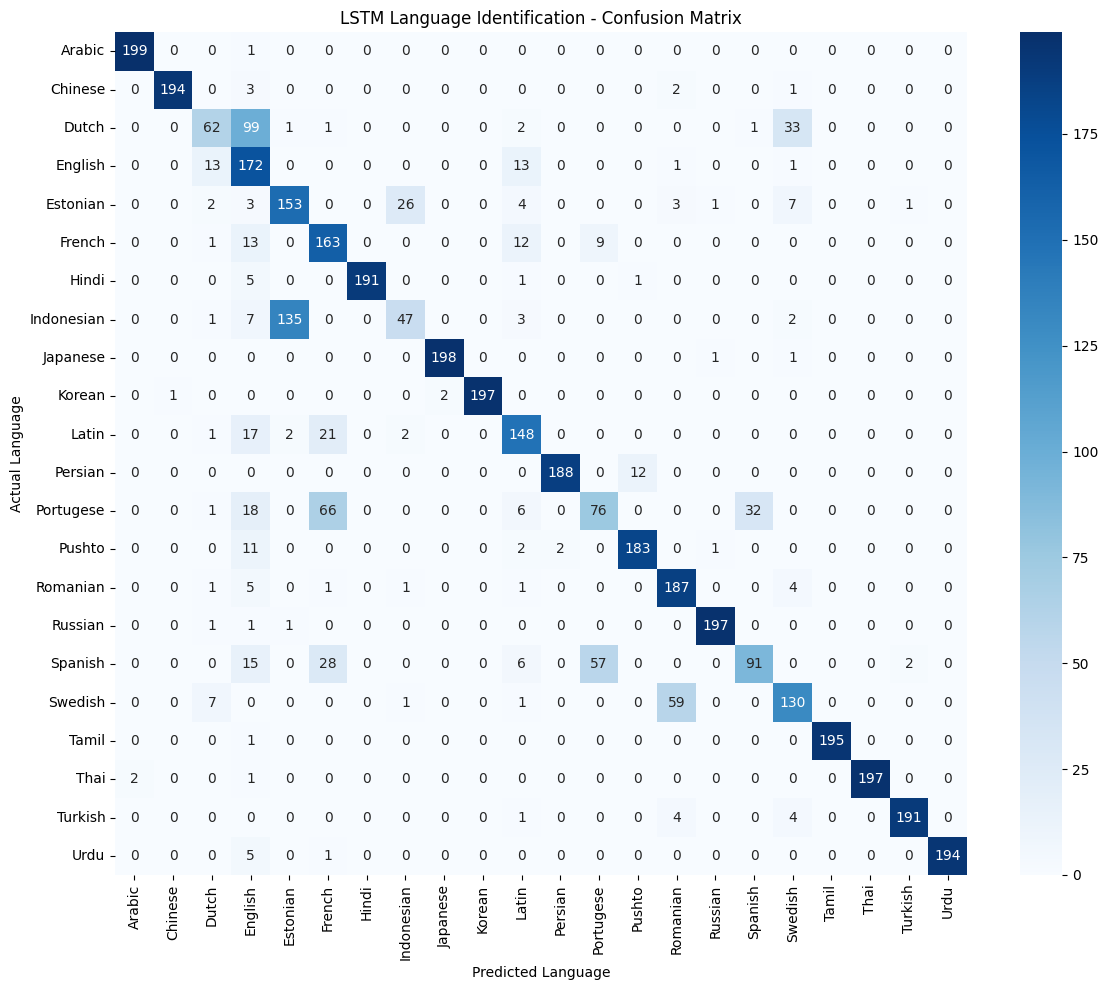

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("LSTM Language Identification - Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Sample sentences
samples = [
    "Hello, how are you today?",
    "Bonjour, comment allez-vous?",
    "Hola, como estas?",
    "Guten Morgen, wie geht es dir?",
    "Ciao, come stai oggi?"
]

# Convert text into sequences
seq = tokenizer.texts_to_sequences(samples)

# Pad sequences
X_samples = pad_sequences(
    seq,
    maxlen=100,
    padding="post",
    truncating="post"
)

# Predict languages
predictions = model.predict(X_samples, verbose=0)

# Display results
for text, pred in zip(samples, predictions):
    idx = np.argmax(pred)

    print("Text:", text)
    print("Predicted Language:", encoder.classes_[idx])
    print("Confidence:", round(float(pred[idx]) * 100, 2), "%")
    print("-" * 40)


Text: Hello, how are you today?
Predicted Language: English
Confidence: 44.24 %
----------------------------------------
Text: Bonjour, comment allez-vous?
Predicted Language: English
Confidence: 34.12 %
----------------------------------------
Text: Hola, como estas?
Predicted Language: Latin
Confidence: 27.98 %
----------------------------------------
Text: Guten Morgen, wie geht es dir?
Predicted Language: English
Confidence: 44.7 %
----------------------------------------
Text: Ciao, come stai oggi?
Predicted Language: Latin
Confidence: 61.89 %
----------------------------------------


In [ ]:

print("Available Languages:")

print(sorted(df["language"].unique()))

print("\nNumber of languages:", df["language"].nunique())


Available Languages:
['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']

Number of languages: 22


Number of samples in each language:

language
Arabic         998
Chinese       1000
Dutch          995
English       1000
Estonian       999
French         990
Hindi          990
Indonesian     975
Japanese      1000
Korean        1000
Latin          953
Persian       1000
Portugese      997
Pushto         993
Romanian      1000
Russian        999
Spanish        996
Swedish        992
Tamil          981
Thai          1000
Turkish       1000
Urdu          1000
Name: count, dtype: int64


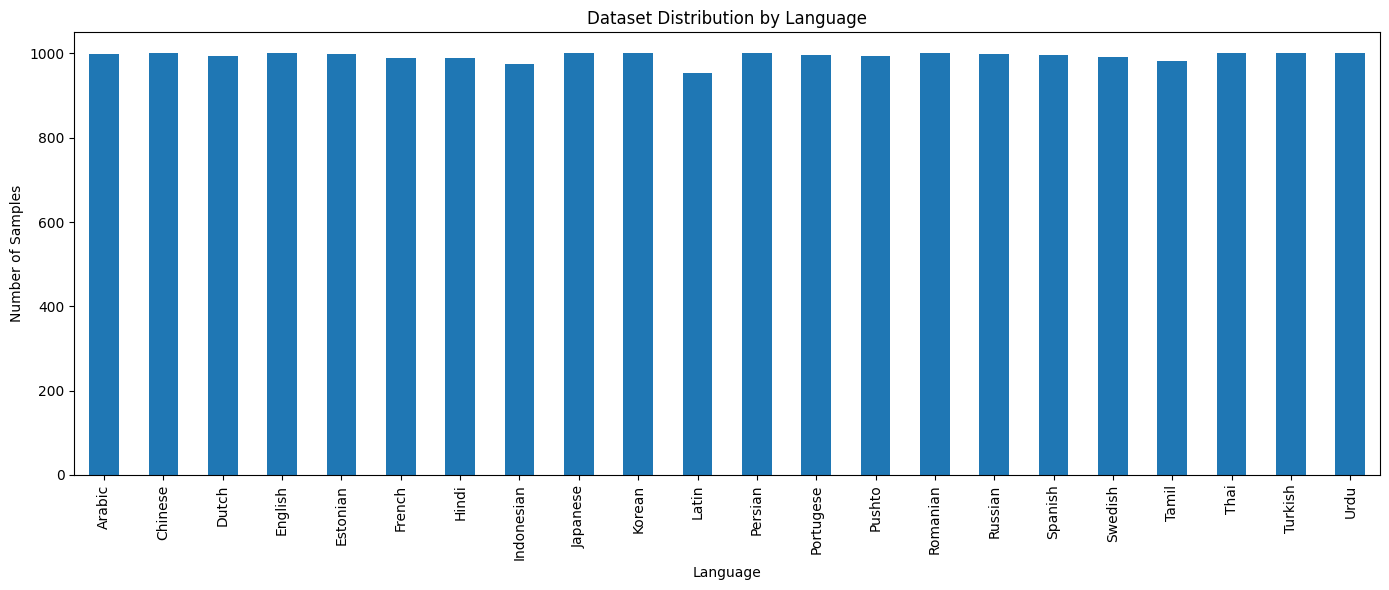

In [ ]:

print("Number of samples in each language:\n")

print(df["language"].value_counts().sort_index())

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
df["language"].value_counts().sort_index().plot(kind="bar")

plt.title("Dataset Distribution by Language")
plt.xlabel("Language")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


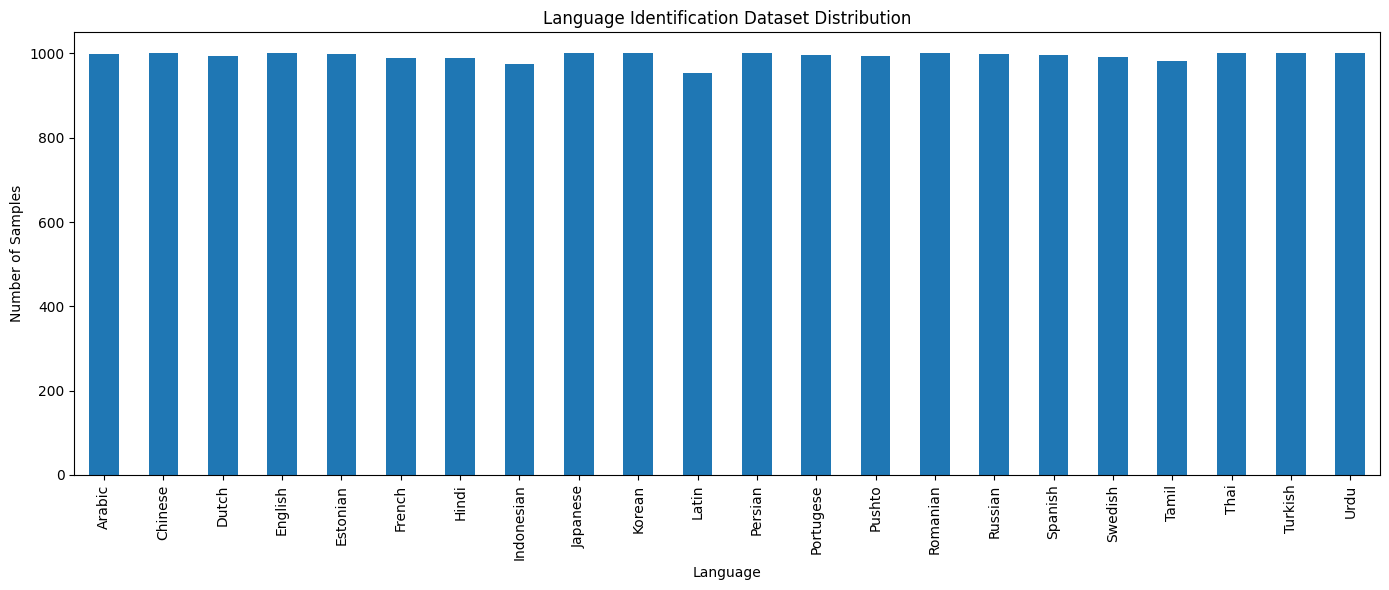

In [ ]:

import matplotlib.pyplot as plt

language_counts = df["language"].value_counts().sort_index()

plt.figure(figsize=(14, 6))
language_counts.plot(kind="bar")

plt.title("Language Identification Dataset Distribution")
plt.xlabel("Language")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


